# Eksploracja danych · Laboratorium 8
## Regresja: ile wyda klient, który zostaje?

**Sytuacja.** W laboratorium 7 drzewo wskazywało, kto odejdzie, a o kuponie decydowaliśmy przy założeniu, że każdy zatrzymany klient to **250 zł** marży. To uproszczenie: klient, który wydaje 300 zł rocznie, jest wart mniej niż ten, który wydaje 6000 zł. Dziś przewidujemy **liczbę**, a nie klasę: ile klient wyda w kolejnym półroczu. To jest **regresja**.

**Dane:** `klienci_wartosc.csv`: ci sami 1206 klienci co w laboratoriach 3 i 7, z nową kolumną:

| Kolumna | Opis |
|---|---|
| `wydatki_6m` | wartość zamówień od 01.10.2026 do 31.03.2027 [zł]; **0** dla klientów, którzy odeszli |
| pozostałe | jak w laboratorium 7 (stan na 30.09.2026), `odszedl` = 1: brak zamówień w tym półroczu |

**Zasada pracy:** luki `___` z komentarzem `UZUPEŁNIJ`. Decyzje i odpowiedzi zapisujemy w komórkach tekstowych. Przed oddaniem: *Kernel → Restart Kernel and Run All Cells*.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import sklearn
print("scikit-learn", sklearn.__version__)
pd.set_option("display.precision", 3)

scikit-learn 1.9.1


## Z1. Rozgrzewka: prosta na kartce

Pięciu klientów: wydatki w ostatnim roku (x) i w kolejnym półroczu (y). Szukamy prostej **y = a + b·x**, dla której suma kwadratów błędów jest najmniejsza (metoda najmniejszych kwadratów). Wzory:

$$b = \frac{\sum (x - \bar x)(y - \bar y)}{\sum (x - \bar x)^2}, \qquad a = \bar y - b \, \bar x$$

Na kartce: policz średnie, odchylenia, b, a, prognozy, błędy (y − prognoza) i **średni błąd bezwzględny** (MAE: średnia z wartości bezwzględnych błędów). Potem sprawdź kodem.

In [ ]:
t = pd.read_csv("pieciu_klientow.csv", sep=";")
t

,klient,wydatki_rok,wydatki_6m
0,A,400,300
1,B,800,300
2,C,1200,700
3,D,1600,700
4,E,2000,1000


In [ ]:
x, y = t["wydatki_rok"], t["wydatki_6m"]
dx, dy = x - x.mean(), y - y.mean()
b = (dx * dy).sum() / (dx ** 2).sum()      # UZUPEŁNIJ: potęga w mianowniku
a = y.mean() - b * x.mean()
prognoza = a + b * x
print(f"b = {b:.3f}   a = {a:.1f}")
print("prognozy:", prognoza.tolist())
print("błędy:   ", (y - prognoza).tolist())
print("MAE:", (y - prognoza).abs().mean())

b = 0.450   a = 60.0
prognozy: [240.0, 420.0, 600.0, 780.0, 960.0]
błędy:    [60.0, -120.0, 100.0, -80.0, 40.0]
MAE: 80.0


**Pytanie:** co oznacza b w złotówkach? Ile według prostej wyda w półroczu klient, który w roku wydał 1000 zł?

*Odpowiedź:* b = 0,45 zł na złotówkę: każda dodatkowa złotówka wydana w roku oznacza średnio o 0,45 zł wyższe wydatki w kolejnym półroczu (a = 60 zł to prognoza dla klienta, który w roku nie wydał nic, czyli wyraz wolny bez praktycznego sensu). Klient, który w roku wydał 1000 zł, wyda według prostej 60 + 0,45 · 1000 = **510 zł**. MAE prostej na pięciu klientach to 80 zł (błędy: 60, −120, 100, −80, 40).

## Z2. Dane: kogo modelujemy?

Klient, który odszedł, ma `wydatki_6m = 0`. To inny proces (odejście) niż „ile wyda, jeśli zostanie”, a odejście przewidywaliśmy już w lab. 7. Regresję uczymy więc tylko na klientach, którzy **zostali**.

In [ ]:
df = pd.read_csv("klienci_wartosc.csv", sep=";", decimal=",")
zostali = df[df["odszedl"] == 0].copy()        # UZUPEŁNIJ: klienci, którzy zostali
print("wszystkich:", len(df), " zostało:", len(zostali))
zostali["wydatki_6m"].describe()

wszystkich: 1206  zostało: 825


count      825.000
mean      1156.022
std       2419.208
min         58.520
25%        253.770
50%        570.570
75%       1293.070
max      40355.480
Name: wydatki_6m, dtype: float64

In [ ]:
# konta firmowe znane z laboratorium 3: wydatki powyżej 20 000 zł rocznie
zostali[zostali["wydatki_zl"] > 20000][["nr_karty", "liczba_zamowien", "wydatki_zl", "wydatki_6m"]]

,nr_karty,liczba_zamowien,wydatki_zl,wydatki_6m
82,101152,74,74343.21,37497.27
204,101106,51,52104.29,2140.00
1107,101143,52,61583.28,40355.48
1138,101134,46,38419.94,23210.99


korelacja (bez firm): 0.797


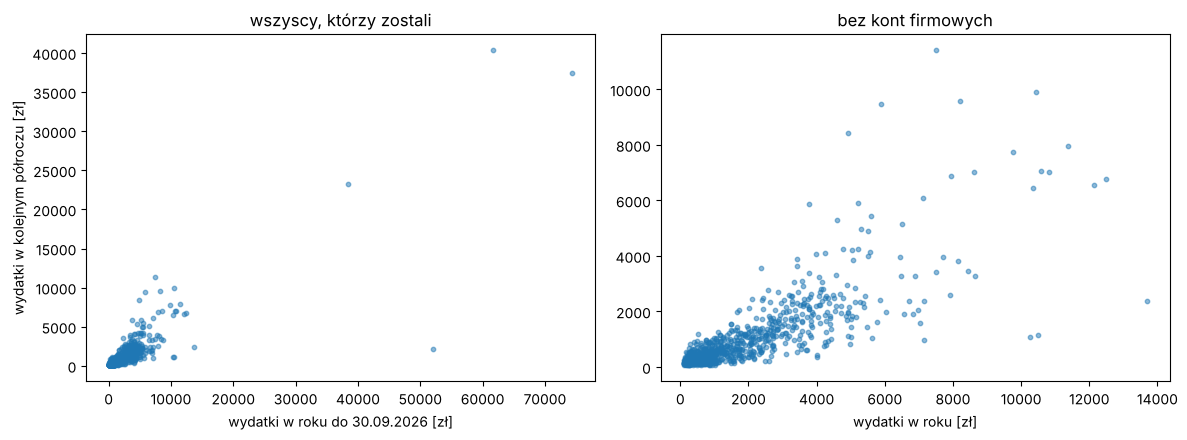

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(zostali["wydatki_zl"], zostali["wydatki_6m"], s=10, alpha=.5)
ax[0].set_xlabel("wydatki w roku do 30.09.2026 [zł]"); ax[0].set_ylabel("wydatki w kolejnym półroczu [zł]"); ax[0].set_title("wszyscy, którzy zostali")
ind = zostali[zostali["wydatki_zl"] <= 20000]
ax[1].scatter(ind["wydatki_zl"], ind["wydatki_6m"], s=10, alpha=.5)
ax[1].set_xlabel("wydatki w roku [zł]"); ax[1].set_title("bez kont firmowych")
plt.tight_layout(); plt.show()
print("korelacja (bez firm):", round(ind["wydatki_zl"].corr(ind["wydatki_6m"]), 3))

**Zapisz:** ilu klientów modelujemy? Czym różnią się konta firmowe? Jak wygląda zależność na wykresie po prawej?

*Odpowiedź:* Modelujemy **825** klientów, którzy zostali (381 odeszło i ma wydatki_6m = 0, więc nie wchodzą do regresji), a po odrzuceniu 4 kont firmowych **821** klientów indywidualnych. Konta firmowe wydają ponad 20 tys. zł rocznie (od ok. 38 do ok. 74 tys. zł), mają 46–74 zamówień i leżą daleko od reszty na osi x, a ich wydatki w półroczu są bardzo rozrzucone (od 2140 zł do ponad 40 tys. zł). Na wykresie po prawej (bez firm) zależność jest rosnąca i w przybliżeniu liniowa (korelacja **0,797**), ale rozrzut punktów rośnie razem z wielkością klienta.

**Z3:** nachylenie prostej z firmami wynosi 0,476, a bez nich 0,530. Cztery punkty (a zwłaszcza konto 101106, które przy ponad 52 tys. zł rocznych wydatków wydało w półroczu tylko 2140 zł) obniżają nachylenie o ok. 10%. To obserwacje wpływowe: jedna firma potrafi przekrzywić prostą dla 800 pozostałych klientów.

## Z3. Jedna firma potrafi przekrzywić prostą

Porównaj prostą dopasowaną do wszystkich, którzy zostali, z prostą bez kont firmowych. Spójrz na konto 101106: w roku wydało ponad 52 tys. zł, w półroczu tylko 2140 zł (utracony kontrakt).

In [ ]:
m_wsz = LinearRegression().fit(zostali[["wydatki_zl"]], zostali["wydatki_6m"])
m_ind = LinearRegression().fit(ind[["wydatki_zl"]], ind["wydatki_6m"])
print(f"z firmami:  wydatki_6m = {m_wsz.intercept_:7.1f} + {m_wsz.coef_[0]:.3f} × wydatki_rok")
print(f"bez firm:   wydatki_6m = {m_ind.intercept_:7.1f} + {m_ind.coef_[0]:.3f} × wydatki_rok")

z firmami:  wydatki_6m =   112.4 + 0.476 × wydatki_rok
bez firm:   wydatki_6m =    16.1 + 0.530 × wydatki_rok


**Decyzja:** dalej modelujemy **klientów indywidualnych** (bez 4 kont firmowych). Konta firmowe obsługuje handlowiec, a 4 obserwacje to za mało, żeby się czegoś o nich nauczyć.

## Z4. Zbiory i punkt odniesienia

Jak w lab. 7: 30% klientów odkładamy na test. Najprostsza prognoza dla każdego: **średnia** wydatków ze zbioru uczącego. Mierzymy trzy błędy:
* **MAE**: średni błąd bezwzględny w zł („mylimy się średnio o … zł”),
* **RMSE**: pierwiastek ze średniego kwadratu błędu; mocniej karze duże pomyłki,
* **R²**: jaka część zmienności wydatków jest wyjaśniona (1 = idealnie, 0 = nie lepiej niż średnia).

In [ ]:
CECHY = ["liczba_zamowien", "wydatki_zl", "sredni_koszyk_zl", "dni_od_ostatniego",
         "udzial_promocji", "udzial_internet", "liczba_kategorii", "zwroty"]
ucz, test = train_test_split(ind, test_size=0.3, random_state=42)
y_test = test["wydatki_6m"]
print("uczący:", len(ucz), " testowy:", len(test))

def ocena(nazwa, prognoza):
    return {"model": nazwa, "MAE_zl": mean_absolute_error(y_test, prognoza),
            "RMSE_zl": mean_squared_error(y_test, prognoza) ** 0.5, "R2": r2_score(y_test, prognoza)}

wyniki = [ocena("średnia ze zbioru uczącego", np.full(len(test), ucz["wydatki_6m"].mean()))]
pd.DataFrame(wyniki)

uczący: 574  testowy: 247


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029


## Z5. Regresja prosta: wydatki w roku → wydatki w półroczu

In [ ]:
prosta = LinearRegression().fit(ucz[["wydatki_zl"]], ucz["wydatki_6m"])      # UZUPEŁNIJ: jedna cecha
print(f"wydatki_6m = {prosta.intercept_:.1f} + {prosta.coef_[0]:.3f} × wydatki_zl")
p_prosta = prosta.predict(test[["wydatki_zl"]])
wyniki.append(ocena("regresja prosta (wydatki_zl)", p_prosta))
pd.DataFrame(wyniki)

wydatki_6m = 27.4 + 0.522 × wydatki_zl


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029
1,regresja prosta (wydatki_zl),375.146,623.255,0.681


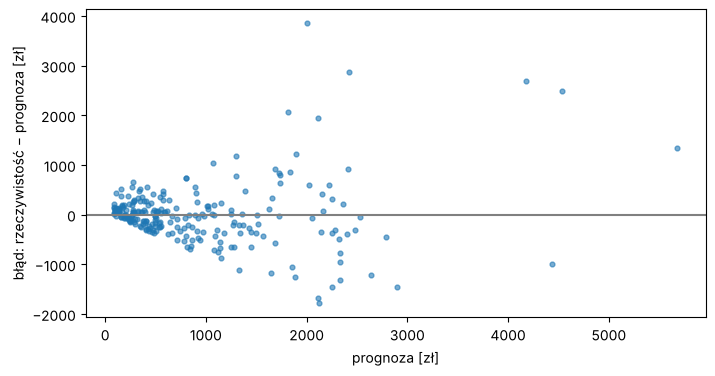

In [ ]:
# wykres błędów: czy model myli się tak samo dla małych i dużych klientów?
plt.figure(figsize=(8, 4))
plt.scatter(p_prosta, y_test - p_prosta, s=12, alpha=.6)
plt.axhline(0, c="grey")
plt.xlabel("prognoza [zł]"); plt.ylabel("błąd: rzeczywistość − prognoza [zł]")
plt.show()

**Pytanie:** jak interpretujesz współczynnik? O ile model jest lepszy od średniej (MAE)? Co widać na wykresie błędów, gdy prognoza rośnie?

*Odpowiedź:* Współczynnik b = 0,522: każda dodatkowa złotówka wydana w ostatnim roku to średnio o ok. 0,52 zł wyższe wydatki w kolejnym półroczu (czyli klient wydaje w półroczu mniej więcej połowę tego, co w roku). MAE spada z 799,6 zł (średnia) do **375,1 zł**, czyli o 424,5 zł (ok. 53%); R² = 0,681, a średnia ma R² ≈ 0.

Na wykresie błędów rozrzut rośnie razem z prognozą (kształt lejka): dla mniejszej połowy prognoz odchylenie standardowe błędu wynosi ok. 211 zł, a dla większej połowy ok. 857 zł. Model myli się więc proporcjonalnie do wielkości klienta, a nie o stałą kwotę, co uzasadnia przejście na logarytmy w Z7.

## Z6. Regresja wieloraka: wszystkie cechy naraz

Każda cecha dostaje własny współczynnik: o ile złotych zmienia się prognoza, gdy cecha rośnie o 1, **a pozostałe się nie zmieniają**.

In [ ]:
wiel = LinearRegression().fit(ucz[CECHY], ucz["wydatki_6m"])
print(pd.Series(wiel.coef_, index=CECHY).round(3))
wyniki.append(ocena("regresja wieloraka (8 cech)", wiel.predict(test[CECHY])))
pd.DataFrame(wyniki)

liczba_zamowien       8.495
wydatki_zl            0.309
sredni_koszyk_zl      1.814
dni_od_ostatniego    -1.894
udzial_promocji     -13.100
udzial_internet      18.204
liczba_kategorii      1.311
zwroty              -82.567
dtype: float64


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029
1,regresja prosta (wydatki_zl),375.146,623.255,0.681
2,regresja wieloraka (8 cech),363.096,596.993,0.708


In [ ]:
# cechy powiązane ze sobą: wydatki = liczba zamówień × średni koszyk
ind[["liczba_zamowien", "wydatki_zl", "sredni_koszyk_zl"]].corr().round(2)

,liczba_zamowien,wydatki_zl,sredni_koszyk_zl
liczba_zamowien,1.00,0.54,0.00
wydatki_zl,0.54,1.00,0.78
sredni_koszyk_zl,0.00,0.78,1.00


**Pytanie:** jaki znak ma współczynnik przy `dni_od_ostatniego` i co znaczy w złotówkach? Dlaczego współczynnik przy `wydatki_zl` spadł w porównaniu z regresją prostą? Czy można z niego wnioskować „podnieśmy klientowi wydatki o 1 zł”?

*Odpowiedź:* Współczynnik przy `dni_od_ostatniego` jest **ujemny: −1,894**. Każdy kolejny dzień od ostatniego zamówienia obniża prognozę wydatków w półroczu o ok. 1,9 zł (przy niezmienionych pozostałych cechach), np. 100 dni to ok. −190 zł. Im dłużej klient milczy, tym mniej wyda.

Współczynnik przy `wydatki_zl` spadł z 0,522 do 0,309, bo wydatki = liczba zamówień × średni koszyk. Te trzy cechy są ze sobą skorelowane (wydatki z liczbą zamówień 0,54, a z koszykiem 0,78), więc część efektu przejęły `liczba_zamowien` (8,5 zł na zamówienie) i `sredni_koszyk_zl` (1,8 zł na złotówkę koszyka). W regresji wielorakiej współczynnik oznacza zmianę „przy pozostałych niezmienionych”, a przy powiązanych cechach to czysto teoretyczne założenie.

**Nie** można wnioskować „podnieśmy klientowi wydatki o 1 zł”: nie da się zwiększyć wydatków, nie zmieniając liczby zamówień lub koszyka, a współczynniki opisują zależności w danych, nie skutki naszych działań (korelacja to nie przyczynowość). MAE poprawia się tylko nieznacznie (363,1 zł wobec 375,1 zł).

## Z7. Logarytm: procenty zamiast złotówek

Pieniądze są skośne: kilku dużych klientów, wielu małych, a błąd rośnie z wielkością klienta (Z5). Po zlogarytmowaniu kwot współczynnik czytamy w **procentach**: wzrost wydatków w roku o 1% → wzrost prognozy o b%. Prognozę wracamy do złotówek funkcją `np.exp`.

In [ ]:
def cechy_log(d):
    return pd.DataFrame({"log_wydatki": np.log(d["wydatki_zl"]), "log_koszyk": np.log(d["sredni_koszyk_zl"]),
                         "dni_od_ostatniego": d["dni_od_ostatniego"]})

logm = LinearRegression().fit(cechy_log(ucz), np.log(ucz["wydatki_6m"]))
print(pd.Series(logm.coef_, index=["log_wydatki", "log_koszyk", "dni_od_ostatniego"]).round(4))
p_log = np.exp(logm.predict(cechy_log(test)))          # UZUPEŁNIJ: z logarytmu z powrotem do złotówek
wyniki.append(ocena("log: wydatki, koszyk, dni", p_log))
pd.DataFrame(wyniki)

log_wydatki          0.516
log_koszyk           0.488
dni_od_ostatniego   -0.003
dtype: float64


,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.584,1120.298,-0.029
1,regresja prosta (wydatki_zl),375.146,623.255,0.681
2,regresja wieloraka (8 cech),363.096,596.993,0.708
3,"log: wydatki, koszyk, dni",342.348,602.828,0.702


**Pytanie:** jak czytasz współczynnik przy `log_wydatki`? A przy `dni_od_ostatniego` (wskazówka: −0,003 na dzień ≈ −0,3% na dzień)? Który model ma najmniejszy MAE?

*Odpowiedź:* `log_wydatki` = 0,516: gdy roczne wydatki klienta są wyższe o 1%, prognoza wydatków w półroczu jest wyższa o ok. **0,52%** (przy stałym koszyku i dniach). Podobnie `log_koszyk` = 0,488 (+1% koszyka daje ok. +0,49%). `dni_od_ostatniego` = −0,003: każdy dzień od ostatniego zamówienia obniża prognozę o ok. **0,3%** (100 dni to ok. −26%, bo efekty się składają).

Najmniejszy MAE ma **model logarytmiczny: 342,3 zł** (wieloraka 363,1 zł, prosta 375,1 zł, średnia 799,6 zł). Warto zauważyć, że RMSE jest tu nieco wyższy niż w wielorakiej (602,8 zł wobec 597,0 zł), co sugeruje, że model logarytmiczny lepiej radzi sobie z typowymi klientami, a nieco gorzej z największymi (RMSE mocniej karze duże pomyłki).

## Z8. A może drzewo? Drzewo regresyjne z lab. 7

Drzewo regresyjne działa jak klasyfikacyjne, tylko w liściu podaje **średnią** wydatków klientów z tego liścia.

In [ ]:
for g in [2, 3, 4, 6]:
    drz = DecisionTreeRegressor(max_depth=g, min_samples_leaf=20, random_state=0).fit(ucz[CECHY], ucz["wydatki_6m"])   # UZUPEŁNIJ: jak w lab. 7
    wyniki.append(ocena(f"drzewo regresyjne, głębokość {g}", drz.predict(test[CECHY])))
tabela = pd.DataFrame(wyniki).round({"MAE_zl": 1, "RMSE_zl": 1, "R2": 3})
tabela

,model,MAE_zl,RMSE_zl,R2
0,średnia ze zbioru uczącego,799.6,1120.3,-0.029
1,regresja prosta (wydatki_zl),375.1,623.3,0.681
2,regresja wieloraka (8 cech),363.1,597.0,0.708
3,"log: wydatki, koszyk, dni",342.3,602.8,0.702
4,"drzewo regresyjne, głębokość 2",462.0,741.8,0.549
5,"drzewo regresyjne, głębokość 3",398.7,669.6,0.632
6,"drzewo regresyjne, głębokość 4",394.1,674.2,0.627
7,"drzewo regresyjne, głębokość 6",387.9,672.2,0.629


**Pytanie:** dlaczego drzewo przegrywa tu z regresją liniową? (Wskazówka: ile różnych prognoz daje drzewo o głębokości 3, a ile prosta?)

*Odpowiedź:* Drzewo o głębokości 3 ma co najwyżej 8 liści, więc daje tylko kilka różnych prognoz (na zbiorze testowym 7), a głębokości 2 aż 4. Regresja liniowa daje każdemu klientowi inną prognozę, rosnącą płynnie z wydatkami. Zależność jest ciągła i w przybliżeniu liniowa (korelacja ≈ 0,8), więc schodkowa funkcja drzewa przybliża ją gorzej: MAE 398,7 zł (gł. 3) wobec 342,3 zł modelu logarytmicznego. Głębsze drzewa poprawiają się tylko trochę (gł. 6: 387,9 zł) i zaczynają się przeuczać. Drzewo nie ekstrapoluje: klientowi większemu niż wszyscy w danych uczących przypisze średnią największego liścia, a prosta będzie rosnąć dalej. Drzewo lepiej sprawdza się tam, gdzie są progi i interakcje (jak przy klasyfikacji odejścia w lab. 7), a nie przy gładkiej zależności liczbowej.

## Z9. Decyzja o kuponie z wartością klienta

Łączymy dwa modele: **ryzyko** odejścia z drzewa z lab. 7 i **wartość** klienta z modelu logarytmicznego (Z7). Marża to 25% wydatków, a zatrzymany klient zostaje z nami co najmniej rok, czyli dwa półrocza. Oczekiwany zysk z kuponu:

**zysk = ryzyko × 0,30 × 0,25 × 2 × prognozowane wydatki w półroczu − 30 zł**

Porównujemy z regułą z lab. 7 (kupon, gdy ryzyko ≥ 0,4: założenie, że każdy zatrzymany klient jest wart 250 zł).

In [ ]:
# model ryzyka z lab. 7 (te same ustawienia)
CECHY7 = CECHY
Xu, Xt, yu, yt = train_test_split(df[CECHY7], df["odszedl"], test_size=0.3, stratify=df["odszedl"], random_state=42)
drzewo7 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0).fit(Xu, yu)

klienci = df[df["wydatki_zl"] <= 20000].copy()                     # klienci indywidualni
klienci["ryzyko"] = drzewo7.predict_proba(klienci[CECHY7])[:, 1]
klienci["wartosc_6m"] = np.exp(logm.predict(cechy_log(klienci)))   # ile wyda, jeśli zostanie
klienci["zysk_kuponu"] = klienci["ryzyko"] * 0.30 * 0.25 * 2 * klienci["wartosc_6m"] - 30   # UZUPEŁNIJ: marża 25%

stara = klienci["ryzyko"] >= 0.4
nowa = klienci["zysk_kuponu"] > 0
print("kuponów, reguła z lab. 7:", stara.sum(), "  nowa reguła:", nowa.sum())
print("w obu:", (stara & nowa).sum(), " tylko w starej:", (stara & ~nowa).sum(), " tylko w nowej:", (~stara & nowa).sum())

kuponów, reguła z lab. 7: 429   nowa reguła: 170
w obu: 125  tylko w starej: 304  tylko w nowej: 45


In [ ]:
cols = ["nr_karty", "wydatki_zl", "dni_od_ostatniego", "ryzyko", "wartosc_6m", "zysk_kuponu"]
print("Przykłady: kupon w starej regule, nie w nowej (wysokie ryzyko, mała wartość)")
print(klienci[stara & ~nowa][cols].sort_values("zysk_kuponu").head(4).round(2).to_string(index=False))
print()
print("Przykłady: kupon tylko w nowej regule (umiarkowane ryzyko, duża wartość)")
print(klienci[~stara & nowa][cols].sort_values("zysk_kuponu", ascending=False).head(4).round(2).to_string(index=False))
print()
print(f"oczekiwany zysk (wg modeli): stara reguła {klienci.loc[stara, 'zysk_kuponu'].sum():.0f} zł, nowa {klienci.loc[nowa, 'zysk_kuponu'].sum():.0f} zł")
print(f"średnia roczna marża (wg modelu) klientów z kuponem w starej regule: {(0.25 * 2 * klienci.loc[stara, 'wartosc_6m']).mean():.0f} zł (założenie z lab. 7: 250 zł)")

Przykłady: kupon w starej regule, nie w nowej (wysokie ryzyko, mała wartość)
 nr_karty  wydatki_zl  dni_od_ostatniego  ryzyko  wartosc_6m  zysk_kuponu
   100948       60.12                234    0.86       45.52       -24.16
   100486       98.12                161    0.49       93.15       -23.10
   101116      109.28                162    0.49      103.48       -22.34
   101135       89.24                178    0.65       80.38       -22.16

Przykłady: kupon tylko w nowej regule (umiarkowane ryzyko, duża wartość)
 nr_karty  wydatki_zl  dni_od_ostatniego  ryzyko  wartosc_6m  zysk_kuponu
   100090     9770.87                 99    0.22     4432.10       113.74
   100786     6495.50                122    0.22     2954.65        65.83
   100450     5209.07                109    0.22     2463.36        49.89
   100685     5491.12                 96    0.22     2348.76        46.18

oczekiwany zysk (wg modeli): stara reguła -2017 zł, nowa 2326 zł
średnia roczna marża (wg modelu) klientów z

**Pytanie:** ile kuponów zmienia adresata? Jakich klientów nowa reguła pomija, a jakich dodaje? Ile naprawdę są warci klienci wysokiego ryzyka w porównaniu z założeniem 250 zł z lab. 7?

*Odpowiedź:* Adresata zmienia **349 kuponów**: 125 klientów dostaje kupon w obu regułach, **304 tylko w starej** (nowa ich pomija) i **45 tylko w nowej** (nowa ich dodaje). Razem 429 kuponów w starej regule i 170 w nowej.

Nowa reguła **pomija** klientów o wysokim ryzyku, ale małej wartości, np. karta 100948: ryzyko 86%, a prognozowane wydatki w półroczu tylko 46 zł (oczekiwany zysk kuponu −24 zł). **Dodaje** klientów o umiarkowanym ryzyku (ok. 22%), ale dużej wartości, np. karta 100090: wydała ponad 9,7 tys. zł w roku, prognoza w półroczu to ok. 4,4 tys. zł (oczekiwany zysk +114 zł).

Klienci wysokiego ryzyka są warci średnio **133 zł** rocznej marży (wg modelu), czyli niemal o połowę mniej niż założenie 250 zł z lab. 7 (mediana rocznych wydatków tych klientów to tylko ok. 372 zł). Oczekiwany zysk wg modeli: stara reguła **−2017 zł** (kupony kosztują więcej, niż przynoszą), nowa **+2326 zł**. Są to wartości oczekiwane z modeli i założeń (30% skuteczności kuponu, koszt 30 zł), a nie zmierzony zysk.

## Zadanie domowe
**D1.** Zapisz model z Z7 jako zdanie dla działu marketingu: „klient, który wydał X zł, z koszykiem Y zł i ostatnim zamówieniem Z dni temu, wyda w półroczu ok. … zł”. Policz dla: 1500 zł, 150 zł, 30 dni oraz 1500 zł, 150 zł, 200 dni.

**D2.** W Z9 zmień skuteczność kuponu na 15%. Ilu klientów dostaje kupon według nowej reguły?

**D3.** (dla chętnych) Dodaj do `app.py` z laboratorium 7 pole „prognozowane wydatki w półroczu” i „oczekiwany zysk z kuponu”. Wzór na prognozę: współczynniki modelu z Z7 (wypisz `logm.intercept_` i `logm.coef_`). Wdróż na Render.

In [ ]:
# D1: model z Z7 w postaci wzoru i prognozy dla dwóch klientów
print(f"ln(wydatki_6m) = {logm.intercept_:.3f} + {logm.coef_[0]:.3f}·ln(wydatki) + {logm.coef_[1]:.3f}·ln(koszyk) {logm.coef_[2]:+.5f}·dni")

def prognoza_6m(wydatki, koszyk, dni):
    x = cechy_log(pd.DataFrame({"wydatki_zl": [wydatki], "sredni_koszyk_zl": [koszyk], "dni_od_ostatniego": [dni]}))
    return float(np.exp(logm.predict(x))[0])

for w, k, d in [(1500, 150, 30), (1500, 150, 200)]:
    print(f"wydał {w} zł, koszyk {k} zł, ostatnie zamówienie {d} dni temu -> ok. {prognoza_6m(w, k, d):.0f} zł w półroczu")

ln(wydatki_6m) = 0.421 + 0.516·ln(wydatki) + 0.488·ln(koszyk) -0.00307·dni
wydał 1500 zł, koszyk 150 zł, ostatnie zamówienie 30 dni temu -> ok. 700 zł w półroczu
wydał 1500 zł, koszyk 150 zł, ostatnie zamówienie 200 dni temu -> ok. 416 zł w półroczu


**D1. Odpowiedź (dla marketingu):** ln(wydatki_6m) = 0,421 + 0,516 · ln(X) + 0,488 · ln(Y) − 0,00307 · Z, czyli wydatki_6m ≈ 1,52 · X^0,516 · Y^0,488 · e^(−0,00307·Z). Po ludzku: *klient, który wydał X zł, z koszykiem Y zł i ostatnim zamówieniem Z dni temu, wyda w półroczu ok. 1,52 · X^0,52 · Y^0,49 · 0,997^Z zł* (każdy dzień bez zamówienia obniża prognozę o ok. 0,3%).

* 1500 zł, koszyk 150 zł, 30 dni: **ok. 700 zł**,
* 1500 zł, koszyk 150 zł, 200 dni: **ok. 416 zł** (o ok. 41% mniej, bo klient „milczy” od 170 dni dłużej).

In [ ]:
# D2: skuteczność kuponu 15% zamiast 30%
skutecznosc = 0.15
klienci["zysk_15"] = klienci["ryzyko"] * skutecznosc * 0.25 * 2 * klienci["wartosc_6m"] - 30
print("kuponów (nowa reguła, skuteczność 15%):", (klienci["zysk_15"] > 0).sum(), " (przy 30%:", nowa.sum(), ")")
print(f"oczekiwany zysk: {klienci.loc[klienci['zysk_15'] > 0, 'zysk_15'].sum():.0f} zł")

kuponów (nowa reguła, skuteczność 15%): 19  (przy 30%: 170 )
oczekiwany zysk: 134 zł


**D2. Odpowiedź:** przy skuteczności kuponu 15% kupon według nowej reguły dostaje **19 klientów** (zamiast 170 przy 30%), a oczekiwany zysk spada z 2326 zł do ok. 134 zł. Skuteczność kuponu jest kluczowym założeniem: gdy kupon działa rzadziej, opłaca się go wysyłać już tylko nielicznym, bardzo wartościowym klientom.